In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

## Análise por canais corrompidos

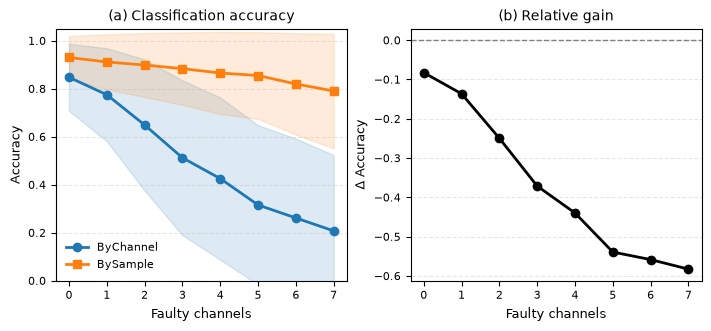

In [4]:
# ======================================================
# Arquivos
# ======================================================
file_bychannel = "EMG_HysersEMG_2D_CNN_128f_128ch_SCE_normminmax_bychannel_adamW_experiment_3_hyser_all.csv"
file_bysample  = "EMG_HysersEMG_2D_CNN_128f_128ch_SCE_normminmax_bysample_adamW_experiment_3_hyser_all.csv"

# ======================================================
# Leitura
# ======================================================
df_channel = pd.read_csv(file_bychannel)
df_sample  = pd.read_csv(file_bysample)

# ======================================================
# Média e desvio padrão por quantidade de canais ruidosos
# ======================================================
stats_channel = (
    df_channel
    .groupby("num_fault_channels")["accuracy"]
    .agg(["mean", "std"])
    .reset_index()
)

stats_sample = (
    df_sample
    .groupby("num_fault_channels")["accuracy"]
    .agg(["mean", "std"])
    .reset_index()
)

# ======================================================
# Ganho relativo
# ======================================================
gain = stats_channel[["num_fault_channels", "mean"]].copy()
gain["delta"] = (
    stats_channel["mean"].values
    - stats_sample["mean"].values
)

# ======================================================
# Estilo IEEE
# ======================================================
plt.rcParams.update({
    "font.size": 9,
    "axes.labelsize": 9,
    "axes.titlesize": 10,
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8
})

fig, axes = plt.subplots(
    1,
    2,
    figsize=(7.0, 3.2),
    constrained_layout=True
)

# ======================================================
# (a) Accuracy média
# ======================================================
ax = axes[0]

x = stats_channel["num_fault_channels"]

ax.plot(
    x,
    stats_channel["mean"],
    color="#1f77b4",
    marker="o",
    linewidth=2,
    label="ByChannel"
)

ax.fill_between(
    x,
    stats_channel["mean"] - stats_channel["std"],
    stats_channel["mean"] + stats_channel["std"],
    color="#1f77b4",
    alpha=0.15
)

ax.plot(
    x,
    stats_sample["mean"],
    color="#ff7f0e",
    marker="s",
    linewidth=2,
    label="BySample"
)

ax.fill_between(
    x,
    stats_sample["mean"] - stats_sample["std"],
    stats_sample["mean"] + stats_sample["std"],
    color="#ff7f0e",
    alpha=0.15
)

ax.set_xlabel("Faulty channels")
ax.set_ylabel("Accuracy")
ax.set_title("(a) Classification accuracy")
ax.set_ylim(0, 1.05)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

ax.legend(frameon=False)

# ======================================================
# (b) Ganho relativo
# ======================================================
ax = axes[1]

ax.plot(
    gain["num_fault_channels"],
    gain["delta"],
    color="black",
    marker="o",
    linewidth=2
)

ax.axhline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1
)

ax.set_xlabel("Faulty channels")
ax.set_ylabel(r"$\Delta$ Accuracy")
ax.set_title("(b) Relative gain")

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

# ======================================================
# Salvar
# ======================================================
plt.savefig(
    "robustness_comparison_ieee.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "robustness_comparison_ieee.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

#Fig. X. Robustness analysis under electrode noise corruption. (a) Mean classification accuracy as a function of the number of noisy channels for models trained with per-channel normalization (ByChannel) and per-sample normalization (BySample). Shaded areas indicate one standard deviation. (b) Relative gain, computed as ΔAccuracy = AccuracyByChannel − AccuracyBySample. Positive values indicate superior robustness of the ByChannel normalization strategy.

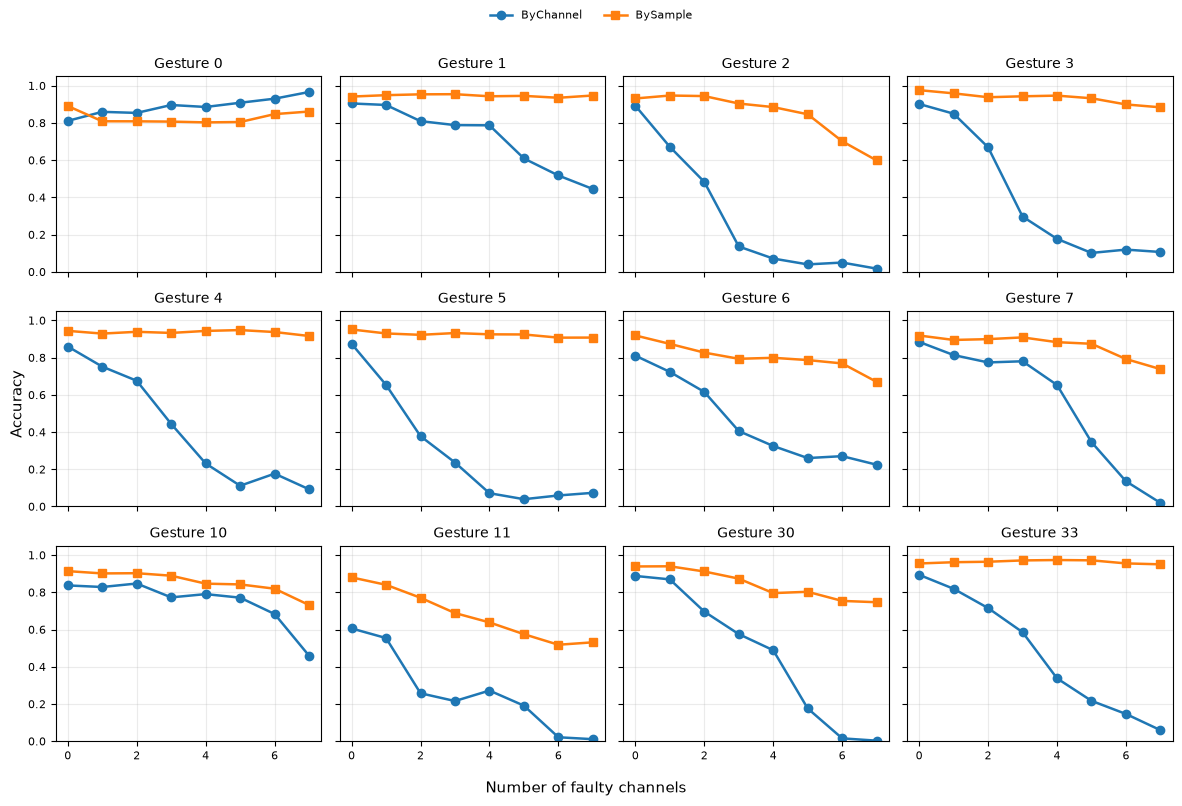

In [5]:

# ======================================================
# Gestos disponíveis
# ======================================================
gestures = sorted(df_channel["gesture"].unique())

# ======================================================
# Figura IEEE
# ======================================================
ncols = 4
nrows = int(np.ceil(len(gestures) / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(12, 8),
    sharex=True,
    sharey=True
)

axes = axes.flatten()

for i, gesture in enumerate(gestures):

    ax = axes[i]

    d1 = df_channel[df_channel["gesture"] == gesture]
    d2 = df_sample[df_sample["gesture"] == gesture]

    s1 = (
        d1.groupby("num_fault_channels")["accuracy"]
        .mean()
        .reset_index()
    )

    s2 = (
        d2.groupby("num_fault_channels")["accuracy"]
        .mean()
        .reset_index()
    )

    ax.plot(
        s1["num_fault_channels"],
        s1["accuracy"],
        marker="o",
        color="#1f77b4",
        linewidth=1.8,
        label="ByChannel"
    )

    ax.plot(
        s2["num_fault_channels"],
        s2["accuracy"],
        marker="s",
        color="#ff7f0e",
        linewidth=1.8,
        label="BySample"
    )

    ax.set_title(f"Gesture {gesture}")
    ax.grid(alpha=0.25)

    ax.set_ylim(0, 1.05)

# remove eixos vazios
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# legenda global
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    ncol=2,
    frameon=False
)

fig.supxlabel("Number of faulty channels")
fig.supylabel("Accuracy")

plt.tight_layout(rect=[0, 0, 1, 0.95])

plt.savefig(
    "accuracy_per_gesture.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "accuracy_per_gesture.pdf",
    bbox_inches="tight"
)

plt.show()

## Análise por gesto

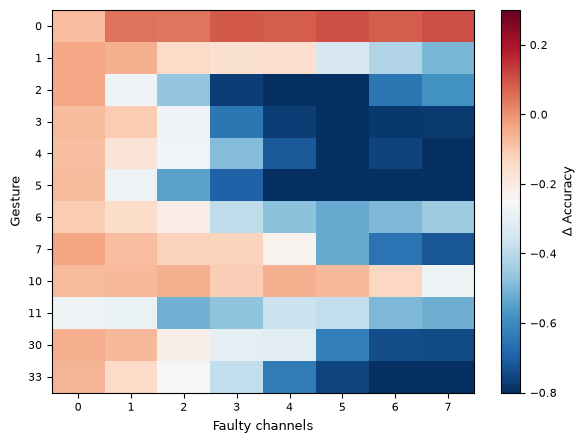

In [14]:

# --------------------------------------------------
# MEAN ACCURACY PER GESTURE
# --------------------------------------------------

acc_channel = (
    df_channel
    .groupby(["gesture", "num_fault_channels"])["accuracy"]
    .mean()
    .reset_index()
)

acc_sample = (
    df_sample
    .groupby(["gesture", "num_fault_channels"])["accuracy"]
    .mean()
    .reset_index()
)

# --------------------------------------------------
# MERGE
# --------------------------------------------------

gain = pd.merge(
    acc_channel,
    acc_sample,
    on=["gesture", "num_fault_channels"],
    suffixes=("_channel", "_sample")
)

gain["delta"] = (
    gain["accuracy_channel"]
    - gain["accuracy_sample"]
)

# --------------------------------------------------
# PIVOT
# --------------------------------------------------

heatmap = gain.pivot(
    index="gesture",
    columns="num_fault_channels",
    values="delta"
)

# --------------------------------------------------
# PLOT
# --------------------------------------------------

fig, ax = plt.subplots(
    figsize=(6.0, 4.5)
)

im = ax.imshow(
    heatmap.values,
    cmap="RdBu_r",
    aspect="auto",
    vmin=-0.8,
    vmax=0.3
)

ax.set_xticks(
    np.arange(len(heatmap.columns))
)

ax.set_xticklabels(
    heatmap.columns
)

ax.set_yticks(
    np.arange(len(heatmap.index))
)

ax.set_yticklabels(
    heatmap.index
)

ax.set_xlabel("Faulty channels")
ax.set_ylabel("Gesture")

cbar = plt.colorbar(
    im,
    ax=ax
)

cbar.set_label(
    r"$\Delta$ Accuracy"
)

plt.tight_layout()

plt.savefig(
    "relative_gain_heatmap.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

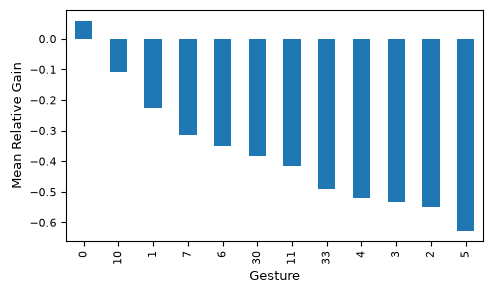

In [15]:
gesture_gain = (
    gain.groupby("gesture")["delta"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(5,3))

gesture_gain.plot.bar(
    color="#1f77b4"
)

plt.ylabel("Mean Relative Gain")
plt.xlabel("Gesture")
plt.tight_layout()
plt.show()

## Análise por sujeito

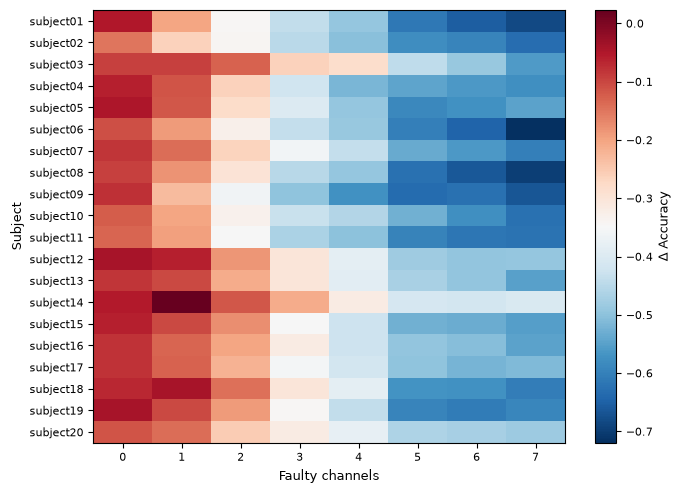

In [10]:
#-----------------------------------------------
# EXTRAI SUJEITO DO CAMINHO
# -----------------------------------------------------

df_channel["subject"] = (
    df_channel["file"]
    .str.extract(r"(subject\d+)")
)

df_sample["subject"] = (
    df_sample["file"]
    .str.extract(r"(subject\d+)")
)

# -----------------------------------------------------
# MÉDIA POR SUJEITO
# -----------------------------------------------------

acc_channel = (
    df_channel
    .groupby(
        ["subject","num_fault_channels"]
    )["accuracy"]
    .mean()
    .reset_index()
)

acc_sample = (
    df_sample
    .groupby(
        ["subject","num_fault_channels"]
    )["accuracy"]
    .mean()
    .reset_index()
)

# -----------------------------------------------------
# GANHO RELATIVO
# -----------------------------------------------------

gain = pd.merge(
    acc_channel,
    acc_sample,
    on=["subject","num_fault_channels"],
    suffixes=("_channel","_sample")
)

gain["delta"] = (
    gain["accuracy_channel"]
    - gain["accuracy_sample"]
)

heatmap = gain.pivot(
    index="subject",
    columns="num_fault_channels",
    values="delta"
)

# -----------------------------------------------------
# PLOT
# -----------------------------------------------------

plt.figure(figsize=(7,5))

im = plt.imshow(
    heatmap.values,
    cmap="RdBu_r",
    aspect="auto"
)

plt.colorbar(
    im,
    label=r"$\Delta$ Accuracy"
)

plt.xticks(
    np.arange(len(heatmap.columns)),
    heatmap.columns
)

plt.yticks(
    np.arange(len(heatmap.index)),
    heatmap.index
)

plt.xlabel("Faulty channels")
plt.ylabel("Subject")

plt.tight_layout()

plt.savefig(
    "subject_gain_heatmap.png",
    dpi=600
)

plt.show()


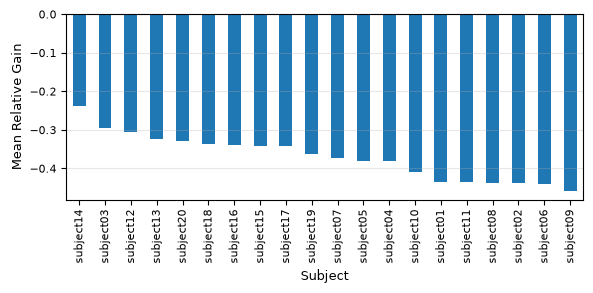

In [11]:
subject_gain = (
    gain.groupby("subject")["delta"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(6,3))

subject_gain.plot.bar(
    color="#1f77b4"
)

plt.ylabel("Mean Relative Gain")
plt.xlabel("Subject")

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "subject_mean_gain.png",
    dpi=600
)

plt.show()


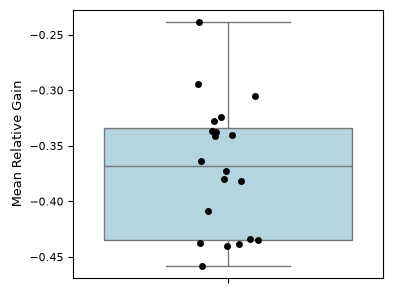

In [12]:
import seaborn as sns

subject_gain_df = (
    gain.groupby(
        ["subject"]
    )["delta"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(4,3))

sns.boxplot(
    y=subject_gain_df["delta"],
    color="lightblue"
)

sns.stripplot(
    y=subject_gain_df["delta"],
    color="black",
    size=5
)

plt.ylabel("Mean Relative Gain")

plt.tight_layout()

plt.show()
